In [23]:
import numpy as np
import mne
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from mspca import mspca
from mne.preprocessing import ICA
from mne.decoding import CSP
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from mne.time_frequency import psd_array_multitaper

import tensorflow as tf
from sklearn.neural_network import MLPClassifier

# Set the datasets

In [2]:
ref = 'C:/ESC5Work/ProjectM5/files'

all_event = {
    'T0' : 'Rest',
    
    'R4_T1' : 'Left_Fist',
    'R8_T1' : 'Left_Fist',
    'R12_T1' : 'Left_Fist',
    
    'R4_T2' : 'Right_Fist',
    'R8_T2' : 'Right_Fist',
    'R12_T2' : 'Right_Fist'
}

label_target = {
    'Rest' : 0,
    'Left_Fist' : 1,
    'Right_Fist' : 2,
}

all_epoch = []
all_epoch_label = []

In [11]:
%%capture
for pat in range(1, 110):
    p_id = f'S{pat:03d}' #S001 #S109
    sub_list = os.path.join(ref, p_id) # C:/ESC5Work/ProjectM5/files/S001
    
    for task in range(1, 15):
        t_id = f'R{task:02d}' # R01 R14
        fin_name = f'{p_id}{t_id}.edf' # S001R01.edf
        fin_path = os.path.join(sub_list, fin_name) # C:/ESC5Work/ProjectM5/files/S001/S001R01.edf
        
        raw = mne.io.read_raw_edf(fin_path, preload=True)
        raw.set_eeg_reference('average', projection=True).apply_proj()
        
        # filtering
        raw.filter(8, 30)
        raw.notch_filter(freqs=50)

        events, events_id = mne.events_from_annotations(raw)
        
        epochs = mne.Epochs(raw, events=events, event_id=events_id, tmin = -0.5, tmax=4.5, preload=True)
        
        epochs_label = []
        rev_id = {i: j for j, i in events_id.items()}
        
        for idx in range(len(epochs)):
            label = epochs.events[idx, 2]
            name_label = rev_id.get(label)
            
            if name_label != 'T0':
                key = f'R{task:02d}_{name_label}'
            else:
                key = name_label
            spe_label = all_event.get(key)
            
            if spe_label:
                if 'Left_Fist' in spe_label:
                    epochs_label.append(label_target['Left_Fist'])
                elif 'Right_Fist' in spe_label:
                    epochs_label.append(label_target['Right_Fist'])
                elif spe_label == 'Rest':
                    epochs_label.append(label_target['Rest'])
                else:
                    epochs_label.append(None)
            else:
                epochs_label.append(None)
                
        valid = [i for i, label in enumerate(epochs_label) if label is not None]
        if not valid:
            del raw, epochs
            continue
        
        epochs_sel = epochs[valid]
        label_sel = np.array([epochs_label[i] for i in valid])
        
        psd, freq = psd_array_multitaper(epochs_sel.get_data(), sfreq=raw.info['sfreq'], fmin=8, fmax=30)
        
        features = psd.reshape(psd.shape[0], -1)
        
        all_epoch.append(features)
        all_epoch_label.append(label_sel)

In [12]:
x = np.concatenate(all_epoch, axis = 0)
y = np.concatenate(all_epoch_label, axis = 0)
print(x.shape)
print(y.shape)

(21488, 7040)
(21488,)


In [13]:
selected_indices = []

for class_id in np.unique(y):
    class_indices = np.where(y == class_id)[0]

    sampled = np.random.choice(class_indices, size=777, replace=False)
    
    selected_indices.extend(sampled)

selected_indices = np.array(selected_indices)
np.random.shuffle(selected_indices)

x_sampled = x[selected_indices]
y_sampled = y[selected_indices]

print(x_sampled.shape, y_sampled.shape)

x = x_sampled
y = y_sampled

(2331, 7040) (2331,)


In [14]:
label, count = np.unique(y, return_counts=True)
rev_target = {i: j for j, i in label_target.items()}
for id, count in zip(label, count):
    name = rev_target.get(id, 'Unknown')

    print(f'{name} = {count}')

Rest = 777
Left_Fist = 777
Right_Fist = 777


In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=123, stratify=y)

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(1631, 7040) (1631,)
(700, 7040) (700,)


# ANN

In [37]:
print("\n--- Training Artificial Neural Network (ANN) ---")

# --- UPDATED: Increased model complexity and training time parameters ---
ann_classifier = MLPClassifier(
    hidden_layer_sizes=(400, 200, 100), # Increased neurons and added a third hidden layer
    activation='relu',
    solver='adam',
    max_iter=1000,                      # Increased max iterations
    alpha=0.0001,
    learning_rate_init=0.00001,
    early_stopping=True,
    n_iter_no_change=5,                # Increased patience for early stopping
    random_state=42,
    verbose=True
)

ann_classifier.fit(x_train, y_train)

print("ANN training complete.")


--- Training Artificial Neural Network (ANN) ---
Iteration 1, loss = 1.10874292
Validation score: 0.304878
Iteration 2, loss = 1.10843011
Validation score: 0.304878
Iteration 3, loss = 1.10819441
Validation score: 0.365854
Iteration 4, loss = 1.10792111
Validation score: 0.365854
Iteration 5, loss = 1.10763903
Validation score: 0.365854
Iteration 6, loss = 1.10738573
Validation score: 0.365854
Iteration 7, loss = 1.10715182
Validation score: 0.365854
Iteration 8, loss = 1.10691563
Validation score: 0.365854
Iteration 9, loss = 1.10666288
Validation score: 0.365854
Validation score did not improve more than tol=0.000100 for 5 consecutive epochs. Stopping.
ANN training complete.


# For c
* 1 = 0.2797427652733119
* 2 = 0.2958199356913183
* 20 = 0.3247588424437299
* 200 = 0.364951768488746

New
* 200 = 0.33440514469453375
* 700 = 0.3553054662379421
* 1500 =  0.3729903536977492

New 2
* 1500 =  0.3504823151125402
* 2000 =  0.3553054662379421
* 2300 =  0.35852090032154343

In [16]:
for c in [0.05, 0.5, 1]:
    svm_classify = SVC(
        C = c,
        kernel='rbf',
        gamma='scale',
        random_state = 42,
        verbose=True
    )
    
    svm_classify.fit(x_train, y_train)
    
    predicted_test = svm_classify.predict(x_test)

    report = [rev_target[i] for i in sorted(np.unique(y))]
    
    accu_test = accuracy_score(y_test, predicted_test)
    print(f'\nAccuracy {c} (test) = ', accu_test)

[LibSVM]
Accuracy 0.05 (test) =  0.3357142857142857
[LibSVM]
Accuracy 0.5 (test) =  0.38
[LibSVM]
Accuracy 1 (test) =  0.37857142857142856


# Overfitting (c for train data)
* 2300 = 0.8845534995977474

In [17]:
predicted_train = svm_classify.predict(x_train)

report = [rev_target[i] for i in sorted(np.unique(y))]

accu_train = accuracy_score(y_train, predicted_train)
print(f'\nAccuracy (train) = ', accu_train)


Accuracy (train) =  0.48007357449417537


Accuracy (train) : 62.42960579243765


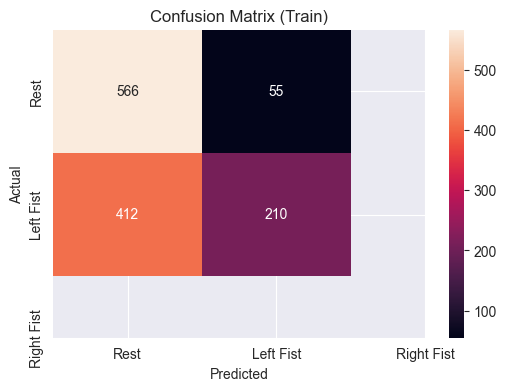

Accuracy (test) : 51.76848874598071


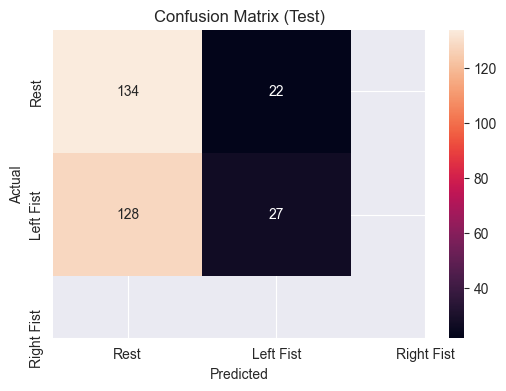

In [10]:
action = ['Rest', 'Left Fist', 'Right Fist']

def confusion_m(conf, name):
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf, annot=True, fmt='g',
                xticklabels=action,
                yticklabels=action)
    
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix '+name)
    plt.show()
    
print('Accuracy (train) :', accu_train*100)
conf = confusion_matrix(y_train, predicted_train)
confusion_m(conf, '(Train)')
print('Accuracy (test) :', accu_test*100)
conf = confusion_matrix(y_test, predicted_test)
confusion_m(conf, '(Test)')